In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv('/content/bank-full.csv', sep=';')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Separate input features and target
X = df.drop('y', axis=1)
y = df['y']

# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True)

# Convert target values into numbers
y = y.map({'no': 0, 'yes': 1})

print("Input features prepared successfully!")
print("Number of input features:", X.shape[1])
print("Target values:")
print(y.value_counts())

Input features prepared successfully!
Number of input features: 42
Target values:
y
0    39922
1     5289
Name: count, dtype: int64


In [4]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Data split successfully!
Training data shape: (36168, 42)
Testing data shape: (9043, 42)


In [5]:
# Create the Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [6]:
# Make predictions using the test data
y_pred = model.predict(X_test)

print("Predictions completed successfully!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

Predictions completed successfully!

First 10 actual values:
[0 0 0 0 0 0 0 1 0 0]

First 10 predicted values:
[0 0 0 0 0 0 0 1 0 0]


In [7]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Subscription', 'Subscribed']
))

Model Evaluation Results
------------------------
Accuracy: 89.84 %

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.98      0.94      7985
     Subscribed       0.64      0.30      0.41      1058

       accuracy                           0.90      9043
      macro avg       0.78      0.64      0.68      9043
   weighted avg       0.88      0.90      0.88      9043



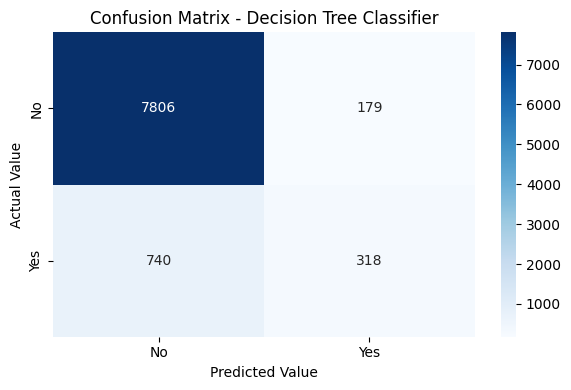

In [8]:
# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Confusion Matrix - Decision Tree Classifier')
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.tight_layout()
plt.show()

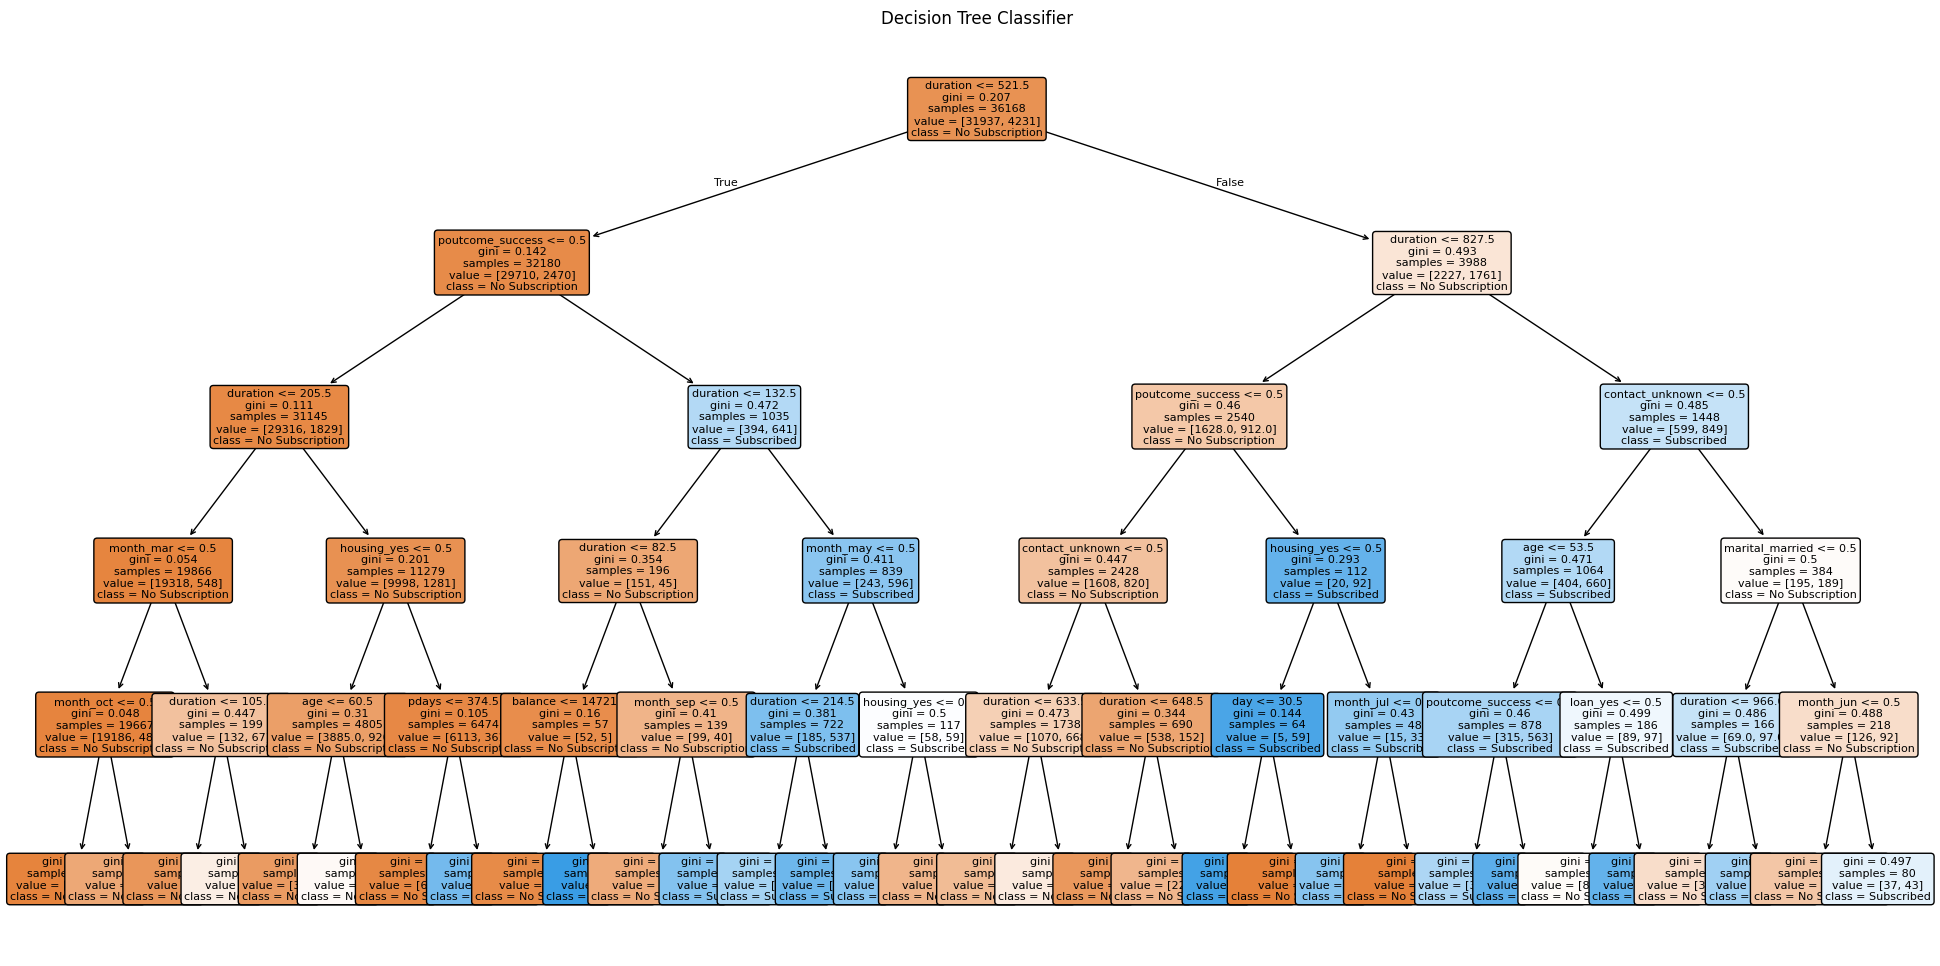

In [9]:
# Visualize the Decision Tree
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No Subscription', 'Subscribed'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title('Decision Tree Classifier')
plt.show()